# AP 155 Lab Exercise
---
## Exercise 9: Minimization

_Instructions_: 
- **Problem 1**
    - Figure: Generate a $1\times2$ showing the two functions and minima markings solved using golden-search
    - Discussion: What happens if a number other than the golden ratio is used to perform the golden section search algorithm? What did you have to do to obtain the maximum?
- **Problem 2**
    - Figure: Plot of $U$ vs $N$ (for a minimum of 20 $N$ points). Compare points calculated from gradient descent with the analytical $U_\text{thom}$ (see link in problem).
    - Discussion: In a single sentence, describe what gradient descent does. How does the parameter $\gamma$ matter? 
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

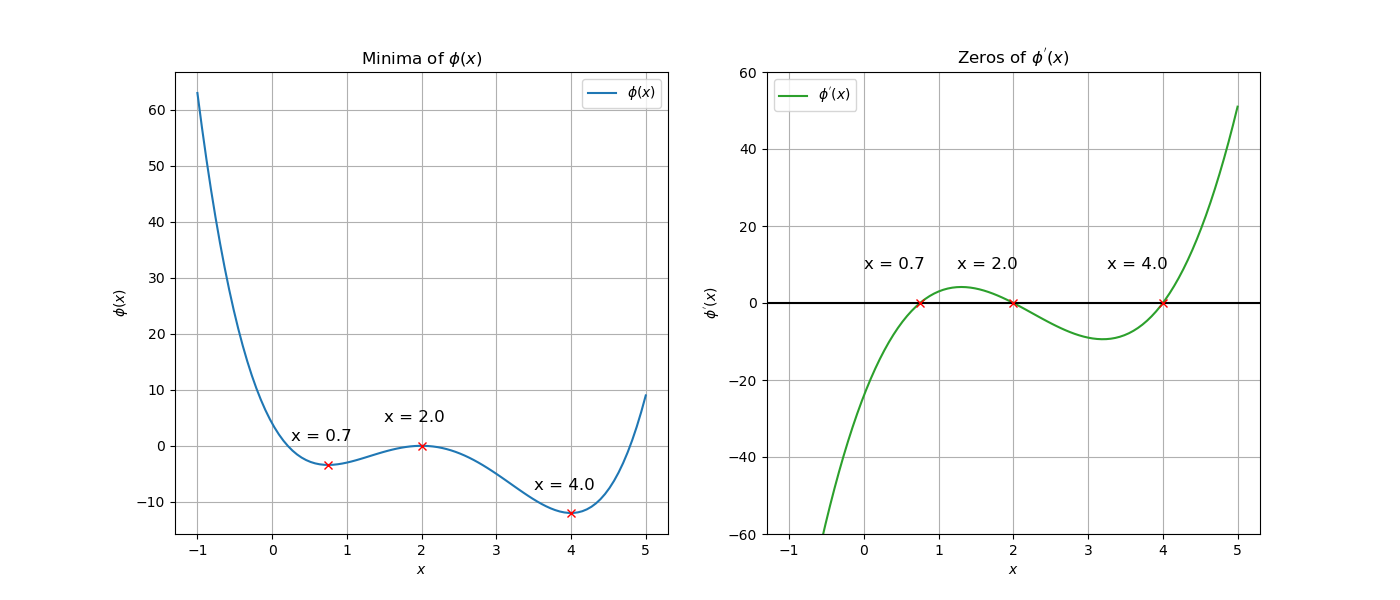

Figure 1. Plot (left) shows function $\phi(x)$ was plotted with marked minima at $x = 0.7,\,4.0$, and marked maximum at $x = 2.0$. The plot (right) shows the analytic derivative $\phi^{'}(x)$, with the zeros plotted at same x-coordinates as the extrema of $\phi(x)$.

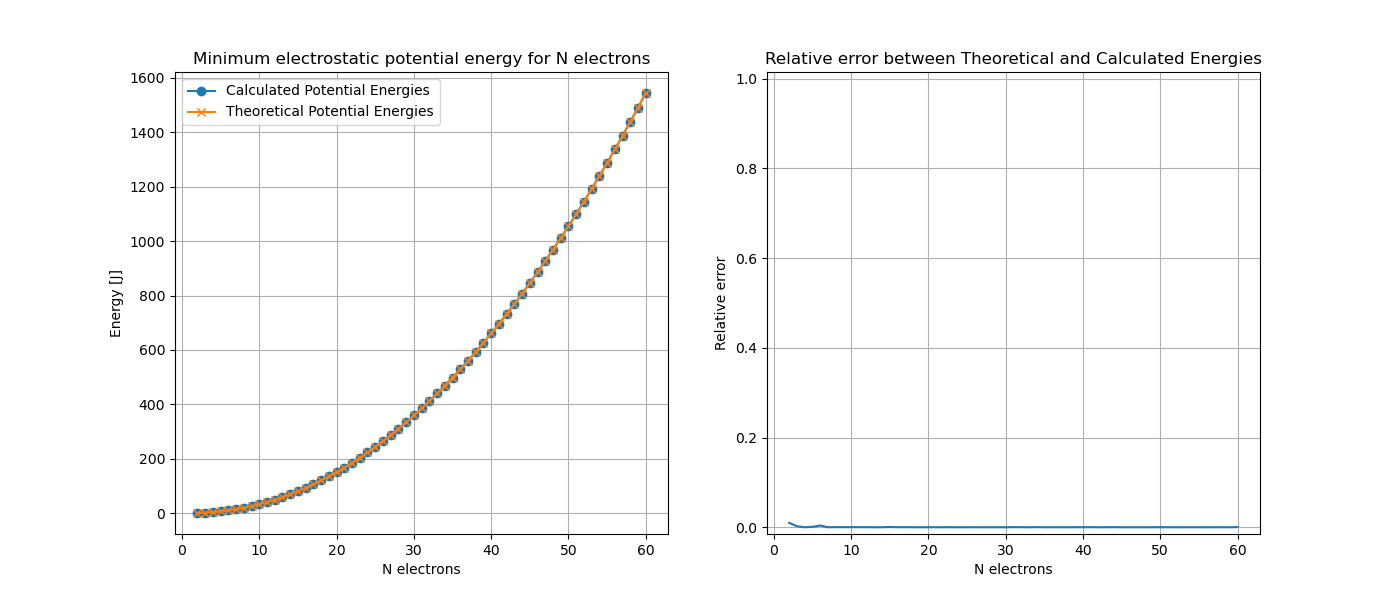

Figure 2. Plot (left) shows the comparison between the theoretical minimum potential energy from the Thomson problem and the calculated minimum potential energy using gradient descent. The plot (right) shows the relative difference between the theoretical data and calculated values. The parameters used in the gradient descent model were ```gamma = 0.0155```, ```kmax = 400```, ```tol = 1.e-8```.

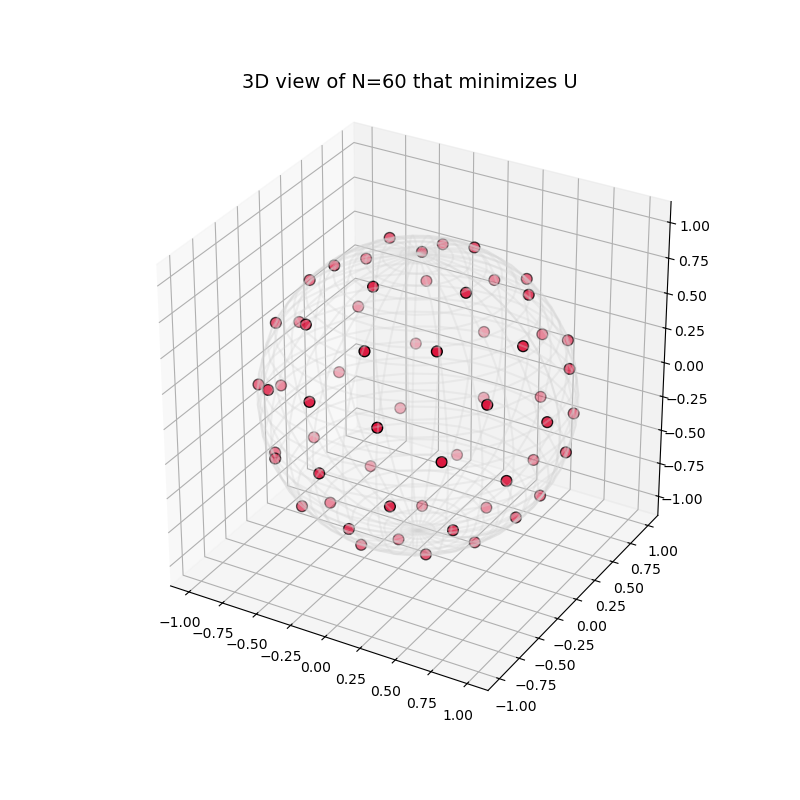

Figure 3. The plot shows the 3D plot of N = 60 electrons that minimizes U. The red dot represents where the electrons are located in the unit sphere. Parameters used here were ```gamma = 1.e-4```, ```kmax = 5000```, ```tol = 1.e-8```.

### Report discussion

In Figure 1, the extrema were found using the golden-search method, which made use of the golden ratio to pick two data points within a region $[x_0, x_1]$. Using any other constant would still allow the algorithm to work as long as that it cuts the region into three. However, this would require an extra evaluation of the function at new interior point, using the golden ratio allows us to reuse the previously calculated constant, skipping an evaluation, which is computationally more efficient. The original ```golden()``` function only found minima. However, multiplying the original function by $-1$ turned the "maxima" into "minima" by reflecting the function across the x-axis. Simply by multiplying $-1$ when evaluating the function at a point allows us the algorithm to find the maxima. The extrema was also verified by plotting the x-coordinates onto the graph of $\phi^{'}(x)$; extremas occur at point where derivative is $0$.

In Figure 2, the gradient descent method was used to compute for the position of the electrons such that the energy is minimized in the Thomson problem. The parameters I found that minimized the relative error the best while keeping the algorithm quick, were ```gamma = 0.0155```, ```kmax = 400```. ```tol = 1.e-8```. The gradient descent algorithm is an iterative algorithm that finds the minimum of the function by calculating the gradient which is a vector that points to the steepest ascent at a point multiplied by; $-1$ to point towrads steepest descent, and $\gamma$ (gamma) which acts as a step size by scaling the vector (learning rate).

You can plot the position of the electrons on a unit circle in the Thomson problem. Figure 3 shows the case for N = 60 electrons. Note that higher parameters were used for the sake of accuracy and that N = 60 was the only case calculated. The position of the dots look vertices of triangular faces, somewhat like an icosphere. The calculated corresponding net electrostatic potential is $U = 1544.701371052$, theoretical value is $U = 1543.830400976$.

### Other comments
- gamma = 0.0155 is interesting...

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

rng = np.random.default_rng(24601)

### Problem 1: Min-maxxing with golden-search

Consider the following equation,

$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4. \tag{1}
$$

- Plot $\phi$ across some domain $x$ (you choose the domain). Visually inspect the plot and record initial estimates for all local minima and local maxima within the interval.
- Implement the Golden-Section Search algorithm (see Section $3$, you may copy it into your code below) to find function minima within a given bracket $[a, b]$ to a specified tolerance. Use your algorithm to locate the precise coordinates $(x^*, \phi(x^*))$ of all local minima and local maxima of Eq. $(1)$.
- **[REPORT FIGURE 1]** Generate a single figure containing a $1 \times 2$ array of subplots:
    - Left Subplot: Plot $\phi(x)$ versus $x$. Overlay and label all identified local minima and maxima using distinct markers.
    - Right Subplot: Plot the analytical first derivative $\phi'(x)$ versus $x$. Mark the zero-crossing points that correspond to the extrema found on the left plot.

In [2]:
import numpy as np
import math
import matplotlib.pyplot as plt

In [3]:
# add the `golden` function here
def golden(phi, x0, x1, multiplier = 1, kmax=200, tol=1.e-8):

    # golden ratio const.
    varphi = 0.5*(1 + math.sqrt(5)) 

    for k in range(1,kmax):

        # we get x2 and x3 in the middle of [x0, x1]
        # the reduction distance d is calculated as GR*(x1-x0)
        # x2 is left point, x3 is right point
        """
        x2 = x1 - d
        x3 = x0 + d
        """
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)

        # note that the calculation above looks different from the highlight comment above it.
        # this is to prevent catastrophic cancellation that may happen from x1-d
        # so the identity GR^2 = GR+1 is used to avoid c.c.

        # if x3 (right point) is less than x2 (left point)
        # then minima must be somewhere in [x2, x1], so we make x2 our new x0 (lower bound)
        """
        purpose of the multiplier is to flip the function on its head so that the "maxima" of the original function becomes the minima
        so obtaining the minima of the flipped function gets the maxima of the orig function.
        """
        if multiplier * phi(x3) < multiplier * phi(x2):
            x0 = x2
        # otherwise, x2 (left point) is less than x3 (right point)
        # then minima must be somewhere in [x0, x3], so we make x3 our new x1 (upper bound)
        else:
            x1 = x3

        # the average between the interior points, this is what we will return if the tolerance is reached
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)

        # terminating condition, if the difference between the upper and lower bounds is less than tolerance, break.
        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    
    return xnew
# add docstrings and comments explaining what the function does

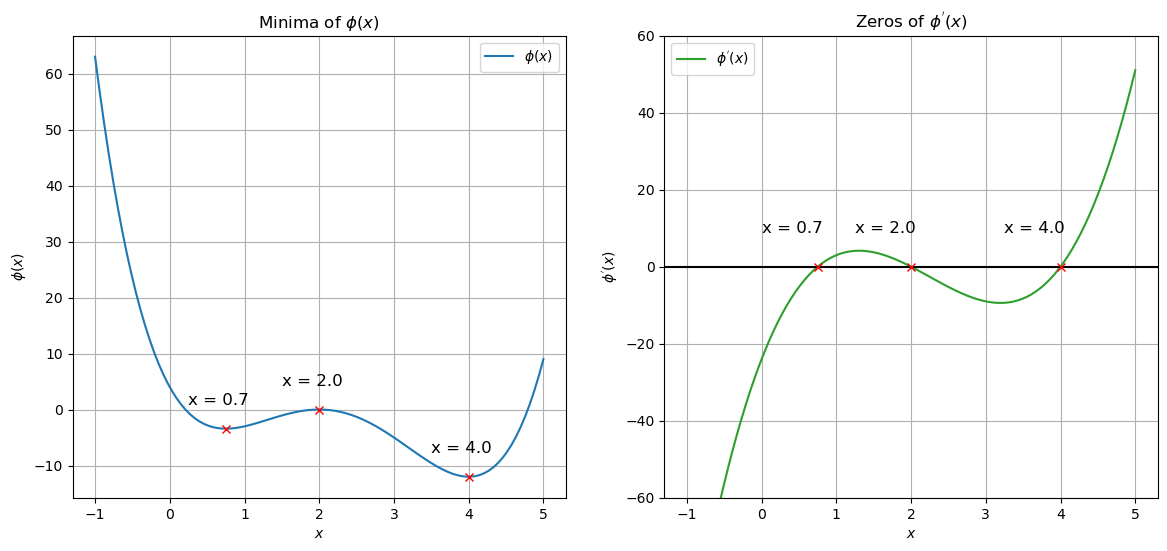

In [4]:
# define Eq. (1)
def phi(x):
    return x * (x * (x * (x - 9) + 25) - 24) + 4

def dphi(x):
    return x * (x * (4*x - 27) + 50) -24

# use golden search to locate minimum
ranges = ((0.0, 1.0),(3.5, 4.5),(1.5, 2.5))
# to locate the maximum, multiply the function evaluated by -1
# minimum: 1; maximum = -1
goal = (1, 1, -1) 

extrema = []
for pair, goal in zip(ranges, goal):
    extremum = golden(phi, pair[0], pair[1], goal)
    extrema.append(extremum)

# report figure 1

# create a set of x to plot phi
xs = np.linspace(-1, 5, 100, endpoint = True)
ys = phi(xs)
dys = dphi(xs)

fig, axs = plt.subplots(1, 2, figsize = (14,6))

# Left subplot: phi(x) vs x, label identified minima
axs[0].plot(xs, ys, label = r"$\phi(x)$")
axs[0].set_title(r'Minima of $\phi(x)$')
axs[0].set_xlabel(r'$x$')
axs[0].set_ylabel(r'$\phi(x)$')
axs[0].grid()
axs[0].legend()

axs[1].plot(xs, dys, 'tab:green', label = r"$\phi^{'}(x)$")
axs[1].axhline(0, color = "black")
axs[1].set_title(r"Zeros of $\phi^{'}(x)$")
axs[1].set_xlabel(r'$x$')
axs[1].set_ylabel(r"$\phi^{'}(x)$")
axs[1].set_ylim(-60,60)
axs[1].grid()
axs[1].legend()

for m in extrema:
    axs[0].plot(m, phi(m), 'rx')
    axs[0].text(m - 0.5, phi(m) + 5, f'x = {m:.1f}', fontsize = 12, verticalalignment = 'center')

    axs[1].plot(m, 0, 'rx')
    axs[1].text(m - 0.75, 10, f'x = {m:.1f}', fontsize = 12, verticalalignment = 'center')
fig.show()
fig.savefig("Problem1.png")

#### Problem 1 code summary
```phi(x)``` and ```dphi(x)``` were defined analytically with the ```golden()``` (Golden-section search method) being used on the former, which was rewritten with a new variable called ```multiplier``` which allows us to find the maxima of the function by letting ```multiplier = -1```. Using tuples to define our ranges and goals (minimizing or maximizing) to somewhat automate the minimizing/maximizing process, we were able to find the extrema and plot it using ```matplotlib```.

---
### Problem 2: Thomson problem with gradient descent ([Wikipedia link](https://en.wikipedia.org/wiki/Thomson_problem))

The goal of the Thomson problem is to determine the minimum electrostatic potential energy configuration given $N$ electrons constrained to the surface of a unit sphere. The electrons repel each other with a force given by Coulomb's law. The total electrostatic potential energy of each $N$-electron configuration may then be expressed as the sum of all pair-wise interaction energies:
$$ U(N) = \sum_{i<j} \frac{1}{r_{ij}}. \tag{2}$$
In context of minimization, we call Eq. $(2)$ our **cost function** or **loss function**. Here, we use simplified units of $e=1$ and $k=1/4\pi\epsilon_0=1$ (the Coulomb constant) without loss of generality.

- Complete the codes below. Add docstrings and comments to all functions.
- Create a 1D array `sphe_params` of initial particle positions in spherical coordinates (random $\theta$, $\phi$, BUT constrained to the surface of a unit sphere i.e. $r=1$).
- Minimize loss function $U(N)$ using gradient descent and `sphe_params` as your initial guess (see Section 3, you may the codes `termcrit`, `gradient`, and `descent` into your code below). Your output should be a 1D array similar to `sphe_params` but the positions that minimizes the potential.
- **[REPORT FIGURE 2]** Plot of $U$ vs $N$. Compare points calculated from gradient descent with the analytical $U_\text{thom}$ (see link in problem).
    - (Optional) Use 3D plotting in Matplotlib to show the geometry for $N=60$ configuration. What does it look like? What is its corresponding net electrostatic potential?

In [5]:
# add the `termcrit` function here

# termcrit calculates the value that is to be compared to the tolerance for the termination condition.
def termcrit(xolds,xnews):
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)
    
# forward difference derivative algorithm done for each component (partial derivative)
def gradient(phi,xs,h=1.e-6):
    n = xs.size
    phi0 = phi(xs)

    # xs*np.ones makes a matrix of rows xs, then transposed to make it a matrix of columns xs.
    # element [i,j] is xs[i]
    # the step size is added to the matrix by scaling an identity matrix by h (woah)
    Xph = (xs*np.ones((n,n))).T + np.identity(n)*h
    # so instead of evaluating it one by one, it can just be evaluated this way (fwd difference)
    grad = (phi(Xph) - phi0)/h
    return grad
    
# add the `descent` function here
def descent(phi, gradient, xolds, gamma=0.15, kmax=200, tol=1.e-8):
    for k in range(1, kmax):

        # first calculates the gradient
        grad = gradient(phi, xolds)
        # and then gets the next point pointed by the gradient, which points towards the minimum
        # essentially works like secant method
        xnews = xolds - gamma * grad
        err = termcrit(xolds, xnews)

        # termination condition
        if err < tol:
            print(f"Converged at iteration {k}")
            return xnews
            
        xolds = np.copy(xnews)
        
    print(f"Reached max iterations ({kmax}).")
    return xnews
# add docstrings and comments explaining what the functions do

In [6]:
# COMPLETE THIS FUNCTION
def spherical_to_cartesian(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)
    
    returns Nx3 array of particle positions in cartesian coords
    """
    N = len(sphe_params) // 2
    thetas = sphe_params[:N]
    phis = sphe_params[N:]
    
    x = R0 * np.sin(thetas) * np.cos(phis) # calculate x from R0, thetas, phis (use np funcs)
    y = R0 * np.sin(thetas) * np.sin(phis) # calculate y from R0, thetas, phis (use np funcs)
    z = R0 * np.cos(thetas) # calculate z from R0, thetas, phis (use np funcs)
    
    return np.column_stack((x, y, z))


def compute_dist(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)

    returns distance matrix where ij is the distance between ith and jth particle
    """
    pos = spherical_to_cartesian(sphe_params, R0)
    diff = pos[:, np.newaxis, :] - pos[np.newaxis, :, :]
    dist_matrix = np.linalg.norm(diff, axis=-1)
    return dist_matrix

def electrostatic_potential(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)

    returns total electrostatic potential
    """
    # Guard: handle 2D matrix input passed from gradient()
    if sphe_params.ndim == 2:
         return np.array([electrostatic_potential(sphe_params[:, j], R0) for j in range(sphe_params.shape[1])])

    d_matrix = compute_dist(sphe_params, R0)
    
    # calculate N dynamically from the input array length
    N_local = len(sphe_params) // 2
    i_upper, j_upper = np.triu_indices(N_local, k=1)
    distances = d_matrix[i_upper, j_upper]
        
    return np.sum(1.0 / distances)

In [7]:
# COMPLETE THIS CODE BLOCK

rng = np.random.default_rng(24601)

N = 10 # number of particles (minimum of 2)

init_theta = rng.uniform(0.0, np.pi, N) # using rng, generate N random data points between 0 and pi
init_phi = rng.uniform(0.0, 2 * np.pi, N) # using rng, generate N random data points between 0 and 2pi

xolds = np.hstack((init_theta, init_phi)) # this is the 1d array where the first half is the thetas and 2nd half is the phis

xnews = descent(electrostatic_potential, gradient, xolds, gamma = 1.e-4, kmax = 5000, tol=1.e-8)# use descent function and `xolds` to calculate the positions that minimizes the cost function
# you may need to test different gamma values (test diff values with your classmates to see which values are closest to theo)

min_potential = electrostatic_potential(xnews) # calculate the "minimized" U given optimized positions

Reached max iterations (5000).


In [8]:
# from N=2 up to 20 (or more), generate the optmized positions and calculate the corresponding minimized potential energies
# for each N, always initialize a random array of positions of N particles

# theoretical list of potential energies from N=2 to N=60
u_thom = [
    0.500000000, 1.732050808, 3.674234614, 6.474691495, 9.985281374,
    14.452977414, 19.675287861, 25.759986531, 32.716949460, 40.596450510,
    49.165253058, 58.853230612, 69.306363297, 80.670244114, 92.911655302,
    106.050404829, 120.084467447, 135.089467557, 150.881568334, 167.641622399,
    185.287536149, 203.930190663, 223.347074052, 243.812760299, 265.133326317,
    287.302615033, 310.491542358, 334.634439920, 359.603945904, 385.530838063,
    412.261274651, 440.204057448, 468.904853281, 498.569872491, 529.122408375,
    560.618887731, 593.038503566, 626.389009017, 660.675278835, 695.916744342,
    732.078107544, 769.190846459, 807.174263085, 846.188401061, 886.167113639,
    927.059270680, 968.713455344, 1011.557182654, 1055.182314726, 1099.819290319,
    1145.418964319, 1191.922290416, 1239.361474729, 1287.772720783, 1337.094945276,
    1387.383229253, 1438.618250640, 1490.773335279, 1543.830400976
] 

# REPORT FIGURE: generate a plot of U vs N 
# compare theoretical and those calculated from gradient descent
# add axes labels and legends

'''
Finding best parameters:
# best so far: gamma = 1.e-2, kmax = 500, tol = 1.e-8
# promising: gamma = 1.e-1, kmax = 500, tol = 1.e-8, nearly zero error for N from 2 to 20 but erratic errors beyond. try to change kmax?
    # lowering kmax makes it a bit worse.
    # highering kmax doesn't do anything
# changed to a higher tol: 1.e-8 to 1.e-10
    # didn't do anything
    # going back to kmax = 250; doesn't do anything
# changed to gamma = 5.e-2
    # yow it extended zero error to N = 30
    # try one more: 75.e-2; it gets worse here
    # try: 2.e-2; insane find, perfect fit until N = 50
# perfect fit: 0.0155 = gamma
'''

min_potential_array = []
for N in range(2,61):

    init_theta = rng.uniform(0.0, np.pi, N)
    init_phi = rng.uniform(0.0, 2 * np.pi, N)

    xolds = np.hstack((init_theta, init_phi))
    
    xnews = descent(electrostatic_potential, gradient, xolds, gamma = 0.0155, kmax = 400, tol = 1.e-8)
    min_potential_array.append(electrostatic_potential(xnews))

Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached max iterations (400).
Reached ma

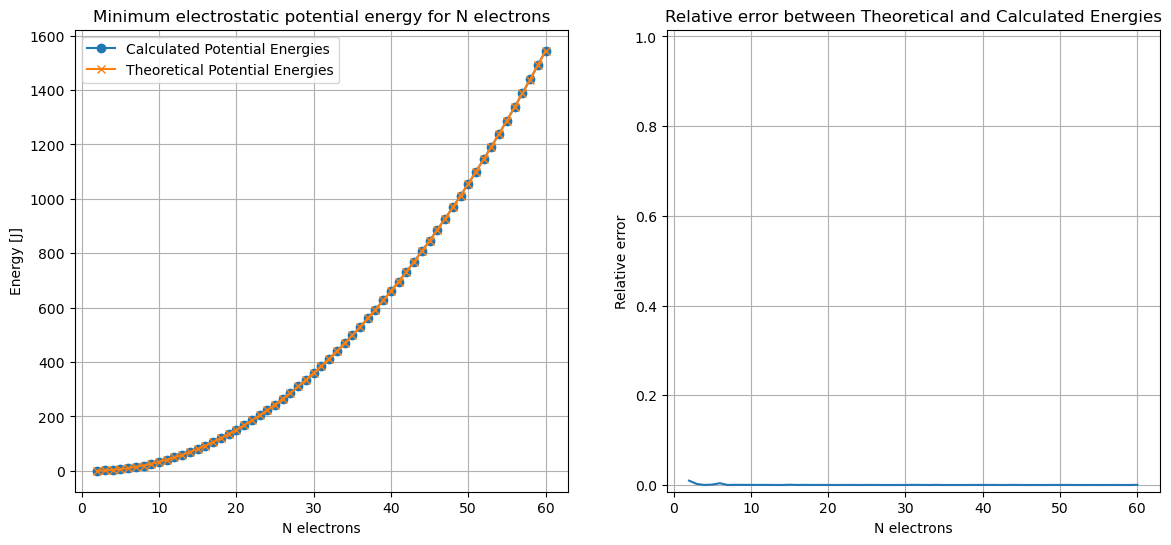

In [9]:
ns = np.arange(2,61,1)

fig, axs = plt.subplots(1, 2, figsize = (14,6))
axs[0].plot(ns, min_potential_array, '-o', label = "Calculated Potential Energies")
axs[0].plot(ns, u_thom, '-x', label = "Theoretical Potential Energies")
axs[0].grid()
axs[0].set_title("Minimum electrostatic potential energy for N electrons")
axs[0].set_ylabel("Energy [J]")
axs[0].set_xlabel("N electrons")
axs[0].legend()

axs[1].plot(ns, abs(np.float32(min_potential_array) - np.float32(u_thom))/np.float32(u_thom))
axs[1].grid()
axs[1].set_ylim(-0.015,1.015)
axs[1].set_title("Relative error between Theoretical and Calculated Energies")
axs[1].set_ylabel("Relative error")
axs[1].set_xlabel("N electrons")

fig.savefig("Problem2.png")

Reached max iterations (5000).
1544.8932177188537


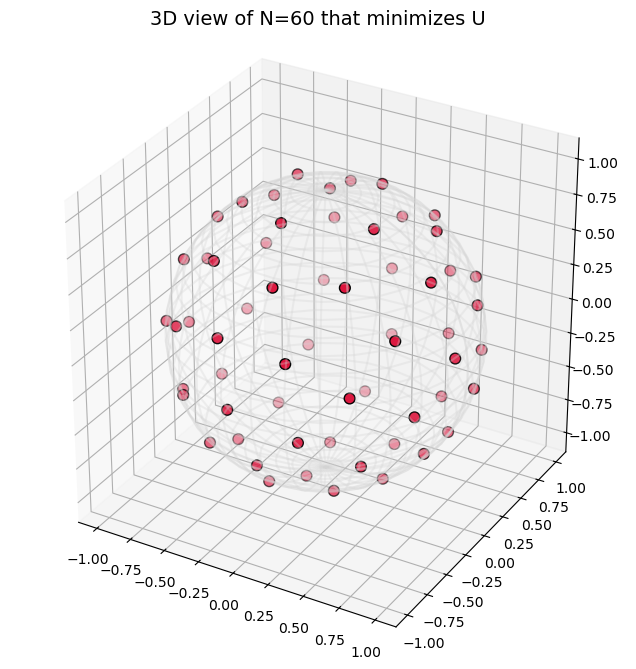

In [10]:
# OPTIONAL
# for 3d plotting of N=60 (it might take a minute to process)

N = 60
init_theta = rng.uniform(0.0, np.pi, N)
init_phi = rng.uniform(0.0, 2 * np.pi, N)
xolds = np.hstack((init_theta, init_phi))
xnews = xnews = descent(electrostatic_potential, gradient, xolds, gamma = 1.e-4, kmax = 5000, tol = 1.e-8)

print(electrostatic_potential(xnews))

# calculate the spherical coordinates of N particles that minimizes
pos = spherical_to_cartesian(xnews)
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Draw wireframe sphere
u = np.linspace(0, 2 * np.pi, 30)
v = np.linspace(0, np.pi, 30)
x_sp = np.outer(np.cos(u), np.sin(v))
y_sp = np.outer(np.sin(u), np.sin(v))
z_sp = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_wireframe(x_sp, y_sp, z_sp, color='lightgrey', alpha=0.3)

# Plot charge positions
ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], color='crimson', s=60, edgecolors='k', depthshade=True)

ax.set_box_aspect([1, 1, 1])
ax.set_title('3D view of N=60 that minimizes U', fontsize=14)
plt.savefig("Problem2_optional.png")
plt.show()

#### Problem 2 code summary

Most of the functions were already given, however we focused more on the "physics" of the problem and how to optimize the gradient descent algorithm in order to accurately represent the theoretical data. The gamma variable acts as a step size or learning rate, a smaller gamma means a finer step size but slower search while a larger gamma means a larger step size but faster search, the kmax determines when does the search stop if termination condition isn't reached, and the tolerance tells the algorithm to stop if the difference is less than it. The balancing of these three parameters are essential to producing a quick yet accurate algorithm.

---
## Section 3: Notes

In [11]:
import numpy as np
import matplotlib.pyplot as plt

### Golden search (minimization tool)

In [12]:
from math import sqrt

def golden(phi, x0, x1, kmax=200, tol=1.e-8):
    varphi = 0.5*(1 + sqrt(5))
    
    for k in range(1,kmax):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)
        
        if phi(x3) < phi(x2):
            x0 = x2
        else:
            x1 = x3
    
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)
    
        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    
    return xnew

#### Example: 

The Buckingham potential is an approximate representation of the potential
energy of interaction between atoms in a solid or gas as a function of the distance $r$ between them:
$$ V(r) = V_0 \left[\left(\frac{\sigma}{r}\right)^6 - e^{-r/\sigma}\right].$$

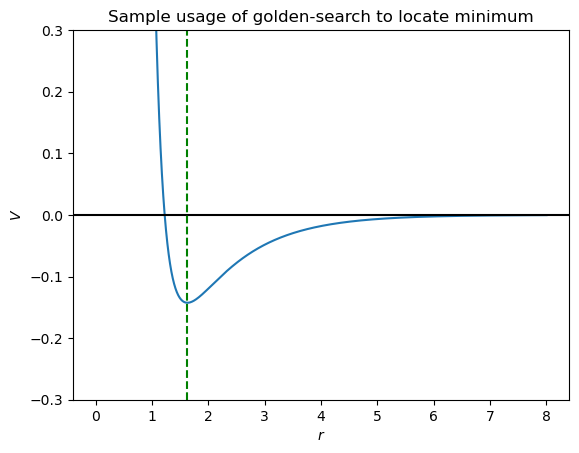

In [13]:
sigma = 1

def V(r, V0=1):
    return V0 * ((sigma / r)**6 - np.exp(-r/sigma))

rlist = np.linspace(1e-3, 8, 1000)
rmin = golden(V, 1.1, 2, kmax=200, tol=1e-8)
plt.plot(rlist, V(rlist))
plt.ylim(-.3, .3)
plt.axhline(0, c='k')
plt.axvline(rmin, c='g', ls='--')
plt.xlabel(r'$r$')
plt.ylabel(r'$V$')
plt.title('Sample usage of golden-search to locate minimum')
plt.show()

### Gradient descent (minimization tool)

In [14]:
def termcrit(xolds,xnews):
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)

def gradient(phi,xs,h=1.e-6):
    n = xs.size
    phi0 = phi(xs)
    Xph = (xs*np.ones((n,n))).T + np.identity(n)*h
    grad = (phi(Xph) - phi0)/h
    return grad

def descent(phi, gradient, xolds, gamma=0.15, kmax=200, tol=1.e-8):
    for k in range(1, kmax):
        grad = gradient(phi, xolds)
        xnews = xolds - gamma * grad
        err = termcrit(xolds, xnews)

        if err < tol:
            print(f"Converged at iteration {k}")
            return xnews
            
        xolds = np.copy(xnews)
        
    print(f"Reached max iterations ({kmax}).")
    return xnews

Converged at iteration 50


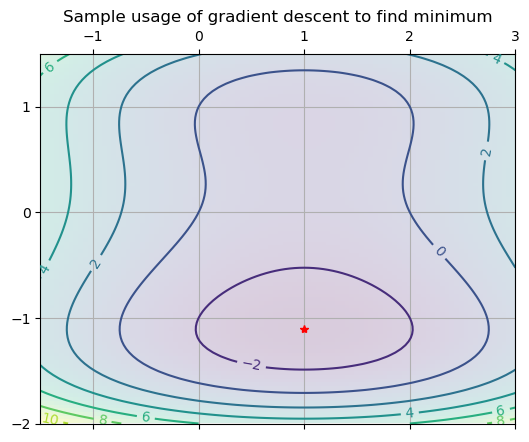

In [15]:
def sample_phi(xs):
    x0, x1 = xs
    return x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1

x = np.linspace(-1.5, 3.0, 100)
y = np.linspace(-2, 1.5, 100)
X, Y = np.meshgrid(x, y)
output = sample_phi(np.array([X, Y]))

xolds = np.array([2.,0.25])
xnews = descent(sample_phi, gradient, xolds)

fig, ax = plt.subplots(dpi=100)

my_extent = [min(x), max(x), min(y), max(y)]
ax.matshow(output, origin="lower", extent=my_extent, alpha=0.2)
ax.plot(*xnews, 'r*')
ax.set_title("Sample usage of gradient descent to find minimum")
csx = ax.contour(X, Y, output)
ax.clabel(csx)
ax.grid(True)
ax.set_aspect('equal')


fig.show()

### Powell's algorithm (minimization tool)

In [16]:
def powell(phi,xolds,nreset=4,cycmax=200,tol=1.e-8):
    n = xolds.size
    for icyc in range(cycmax):
        xnews = np.copy(xolds)
    
        if icyc%nreset==0:
            U = np.identity(n)
        for k in range(n):
            ga = golden(lambda g: phi(xnews+g*U[:,k]),-10.,+10.)
            xnews += ga*U[:,k]
        U[:,:-1] = U[:,1:]
        U[:,-1] = xnews - xolds
        ga = golden(lambda g: phi(xolds+g*U[:,-1]),-10.,+10.)
        xolds += ga*U[:,-1]
        
        err = termcrit(xolds,xnews)
        # print(icyc, xnews, err, phi(xnews))
        if err < tol:
            break
    else:
        xnews = None
    return xnews

[ 1.00000002 -1.10715988]


Text(0.5, 1.0, "Sample usage of powell's algorithm to find minimum")

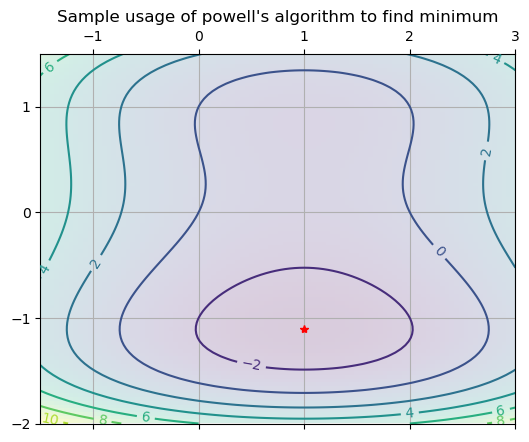

In [17]:
def phi_func(xs):
    x0,x1 = xs
    return x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1

x0 = np.linspace(-1.5, 3.0, 100)
x1 = np.linspace(-2, 1.5, 100)
X0, X1 = np.meshgrid(x, y)
output = phi_func(np.array([X0, X1]))

fig, ax = plt.subplots(1, 1, dpi=100)

xolds = np.array([2.,0.25])
xnews = powell(sample_phi, xolds); print(xnews)
ax.plot(*xnews, 'r*')

my_extent = [min(x0), max(x0), min(x1), max(x1)]
ax.matshow(output, origin="lower", extent=my_extent, alpha=0.2)
csx = ax.contour(X0, X1, output)
ax.clabel(csx)
ax.grid(True)
ax.set_aspect('equal')
ax.set_title("Sample usage of powell's algorithm to find minimum")

### Plotting subplots

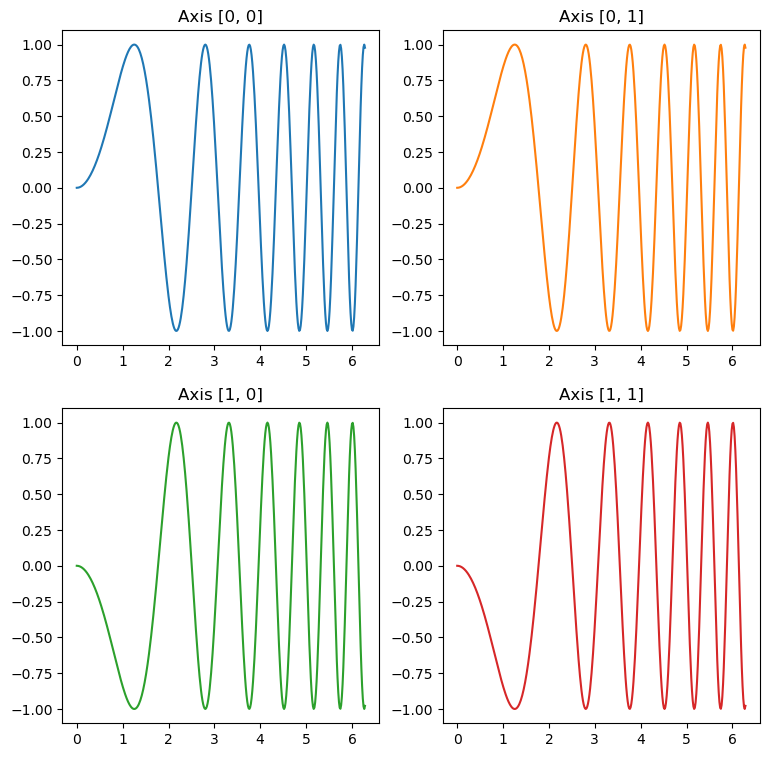

In [18]:
#sample incomplete 2 by 2 plot 

x = np.linspace(0, 2 * np.pi, 400)
y = np.sin(x ** 2)

fig, axs = plt.subplots(2, 2, figsize = (9,9))

axs[0, 0].plot(x, y)
axs[0, 0].set_title('Axis [0, 0]')

axs[0, 1].plot(x, y, 'tab:orange')
axs[0, 1].set_title('Axis [0, 1]')

axs[1, 0].plot(x, -y, 'tab:green')
axs[1, 0].set_title('Axis [1, 0]')

axs[1, 1].plot(x, -y, 'tab:red')
axs[1, 1].set_title('Axis [1, 1]')

fig.show()

### Others

(Optional) Visualizing the vector field.
This is not required to get the method running, but it's a nice way for us to realize that we are indeed working with vector fields. Also, the mesh-forming syntax here will be useful for our succeeding activities.

In [19]:
def nonlin_func(x):
    # From Eq. 5.72 in Gezerlis, annotating Code 5.5
    #* Note: we expect the input and output of the function
    #  to be BOTH vectors. If x is a k-dimensional vector,
    #  then f(x) should also return a k-dimensional vector.  
    x0, x1 = x[0], x[1]

    # This is the same as defining f0 and f1 separately. We
    # just casted the output directly into the array
    return np.array([
        (x0**2) - (2*x0) + (x1**4) - (2*x1**2) + (x1),
        (x0**2) + (x0) + (2*x1**3) - (2*x1**2) - (1.5*x1) - 0.05   
    ])

x_test = np.array([0.5, 0.6])
print(nonlin_func(x_test))

[-0.7404 -0.488 ]


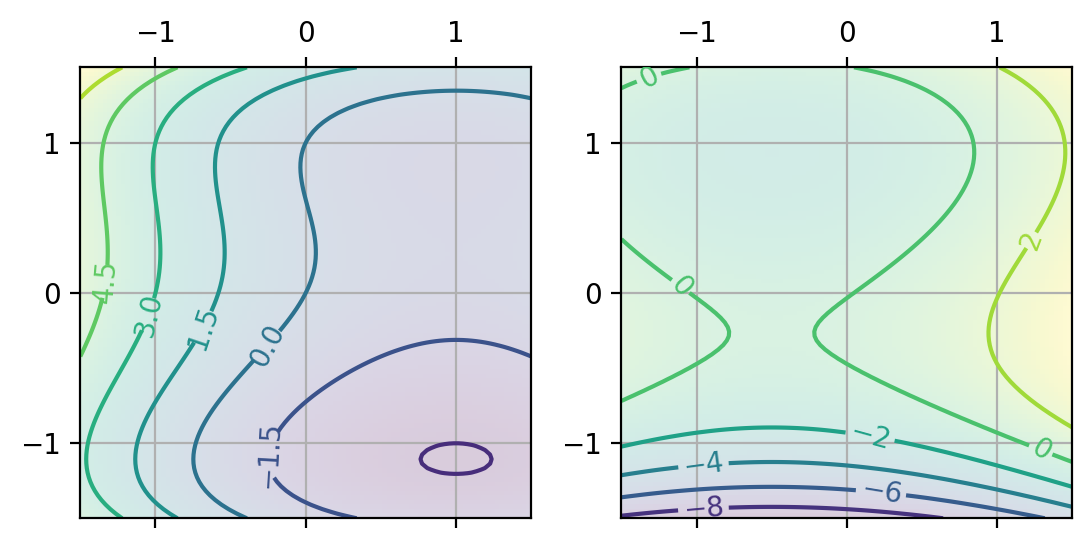

In [20]:
x = np.linspace(-1.5, 1.5, 100)
y = np.linspace(-1.5, 1.5, 100)
X, Y = np.meshgrid(x, y)
output = nonlin_func(np.array([X, Y]))

fig, axs = plt.subplots(1, 2, dpi=200)

my_extent = [min(x), max(x), min(y), max(y)]
axs[0].matshow(output[0], origin="lower", extent=my_extent, alpha=0.2)
csx = axs[0].contour(X, Y, output[0])
axs[0].clabel(csx)

axs[1].matshow(output[1], origin="lower", extent=my_extent, alpha=0.2)
csy = axs[1].contour(X, Y, output[1])
axs[1].clabel(csy)

for ax in axs:
    ax.grid(True)

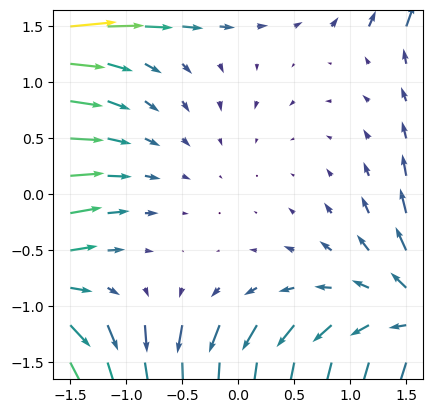

In [21]:
x = np.linspace(-1.5, 1.5, 10)
y = np.linspace(-1.5, 1.5, 10)
X, Y = np.meshgrid(x, y)
output = nonlin_func(np.array([X, Y]))

fig, ax = plt.subplots(1, dpi=100)

mag = np.sqrt(output[0]**2 + np.sqrt(output[1]**2))
ax.quiver(X, Y, output[0], output[1], mag)
ax.grid(alpha=0.2)
ax.set_aspect("equal")

In [22]:
import numpy as np

def backsub(U,bs):
    """
    Input:
        * U matrix
        * bs known vector
    Output: solve column vector using back substitution
    """
    n = bs.size
    xs = np.zeros(n)
    for i in reversed(range(n)):
        xs[i] = (bs[i] - U[i,i+1:]@xs[i+1:])/U[i,i]
    return xs

def gauelimpivot(inA,inbs):
    """
    Input:
        * inA matrix
        * inbs known vector
    Output: solve column vector with gaussian elimination
    """
    A = np.copy(inA)
    bs = np.copy(inbs)
    n = bs.size
    for j in range(n-1):
        k = np.argmax(np.abs(A[j:,j])) + j
        if k != j:
            A[j,:], A[k,:] = A[k,:], A[j,:].copy()
            bs[j], bs[k] = bs[k], bs[j]
    
        for i in range(j+1,n):
            coeff = A[i,j]/A[j,j]
            A[i,j:] -= coeff*A[j,j:]
            bs[i] -= coeff*bs[j]
            
    xs = backsub(A,bs)
    return xs

def termcrit(xolds,xnews):
    """
    Input:
        * xolds older estimates
        * xnews newest estimates
    Output: solve termination criterion with numpy
    """
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)

def fs(xs):
    """
    Input:
        * xs tuple input
    Output: scalar outputs from two functions given one set of input
    """
    x0, x1 = xs
    f0 = x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1
    f1 = x0**2 + x0 + 2*x1**3 - 2*x1**2 - 1.5*x1 - 0.05
    return np.array([f0,f1])

def jacobian(fs,xs,h=1.e-4):
    """
    Input:
        * fs : function of system of equations taking 1d array `xs` and returns 1d array of func values
        * xs : 1d array representing the eval point
        * h : float, optional 
    
    Output: builds jacobian matrix Jf and array containing values evaluated at xs
    """
    n = xs.size
    iden = np.identity(n)
    Jf = np.zeros((n,n))
    fs0 = fs(xs)
    for j in range(n):
        fs1 = fs(xs+iden[:,j]*h)
        Jf[:,j] = (fs1 - fs0)/h
    return Jf, fs0

def multinewton(fs,jacobian,xolds,kmax=200,tol=1.e-8):
    """
    Input:
        * fs : function of system of equations taking 1d array `xs` and returns 1d array of func values
        * jacobian : calcs the jacobian
        * xolds : 1d array containing the initial guess vector
        * kmax : no of iterations
        * tol : tolerance for convergence
    
    Output: 1d array of the approximate root vector if converged
    """
    for k in range(1,kmax):
        Jf, fsxolds = jacobian(fs, xolds)
        xnews = xolds + gauelimpivot(Jf, -fsxolds)
        err = termcrit(xolds, xnews)
        print(k, xnews, err)
        if err < tol:
            break
        
        xolds = np.copy(xnews)
    else:
        xnews = None
    return xnews

if __name__ == '__main__':
    xolds = np.array([1.,1.])
    xnews = multinewton(fs, jacobian, xolds)
    print(xnews); print(fs(xnews))

1 [0.68327197 1.99963178] 0.9634539886260238
2 [0.38286992 1.62816875] 1.0127537609121247
3 [0.56358881 1.4144802 ] 0.4717294772974023
4 [0.5900614  1.32693341] 0.11084089956296016
5 [0.59215596 1.3126421 ] 0.014424613090514531
6 [0.59218625 1.31228241] 0.00032525133774643014
7 [0.59218627 1.31228212] 2.5249741194196077e-07
8 [0.59218627 1.31228212] 4.335881037833639e-11
[0.59218627 1.31228212]
[3.97459843e-14 2.77972090e-14]
